# The Grand Tour: from a raw light curve to a planet's posterior

**Level:** beginner to intermediate · **Run time:** ~2 min (most of it the download) · This notebook appears in the tutorials of [wotan](https://github.com/hippke/wotan), [TLS](https://github.com/hippke/tls) and [pizzetti](https://github.com/hippke/pizzetti).

**Covers:** downloading a TESS light curve with [lightkurve](https://lightkurve.github.io/lightkurve/), detrending
with [wotan](https://github.com/hippke/wotan), finding the planet with
[Transit Least Squares (TLS)](https://github.com/hippke/tls), fitting it with importance sampling in
[pizzetti](https://github.com/hippke/pizzetti), and reading the posterior

Every step of finding and characterising a transiting planet, from the light curve on the archive to the
posterior of its parameters, in one notebook. We pretend not to know the planet: LHS 3844 b, a hot rocky planet
that orbits a small red dwarf every 11 hours, found in the first sector of TESS.

| step | tool | figure |
|---|---|---|
| 1. download the light curve | lightkurve | 1 |
| 2. remove stellar and instrumental trends | wotan | 2 |
| 3. search for transits | TLS | 3, 4 |
| 4. detrend again, protecting the transits | wotan | 5 |
| 5. fit the transit, limb darkening included | pizzetti (importance sampling) | 6, 7 |
| 6. physical quantities | numpy | 8 |

You need:

```bash
pip install "pizzetti[fit]" lightkurve wotan transitleastsquares corner matplotlib
```

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # lightkurve warns about an optional package
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
from wotan import flatten, transit_mask
from transitleastsquares import transitleastsquares, catalog_info
import pizzetti

## Step 1: download the light curve

TESS sector 1, one point every 2 minutes, from the SPOC pipeline. We remove missing values and normalise the flux
to a median of 1.

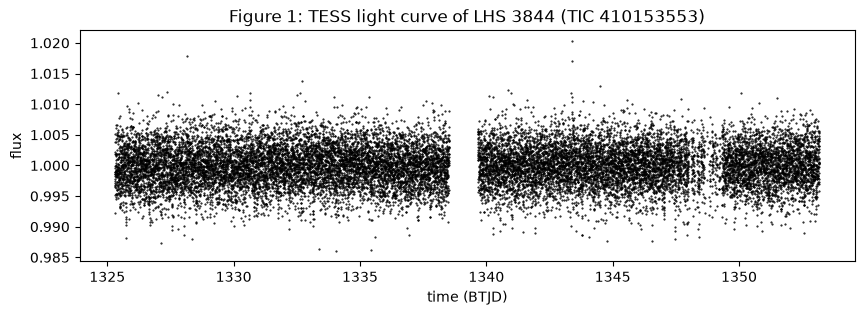

In [2]:
search = lk.search_lightcurve("LHS 3844", mission="TESS", author="SPOC", exptime=120, sector=1)
lc = search.download().remove_nans().normalize()
time = lc.time.value             # days (BTJD = BJD - 2457000)
flux = lc.flux.value
tic = lc.meta["TICID"]           # the star's TESS Input Catalog number

plt.figure(figsize=(10, 3))
plt.plot(time, flux, "k.", ms=1)
plt.xlabel("time (BTJD)"); plt.ylabel("flux")
plt.title(f"Figure 1: TESS light curve of LHS 3844 (TIC {tic})");

Nothing obvious: the transits are 0.4% deep, smaller than the scatter of single points.

## Step 2: detrend with wotan

A robust running average (the biweight) over half a day follows the slow variations of the star and the
instrument, but not short dips like transits. We divide it out. We don't know the planet yet, so nothing is masked.

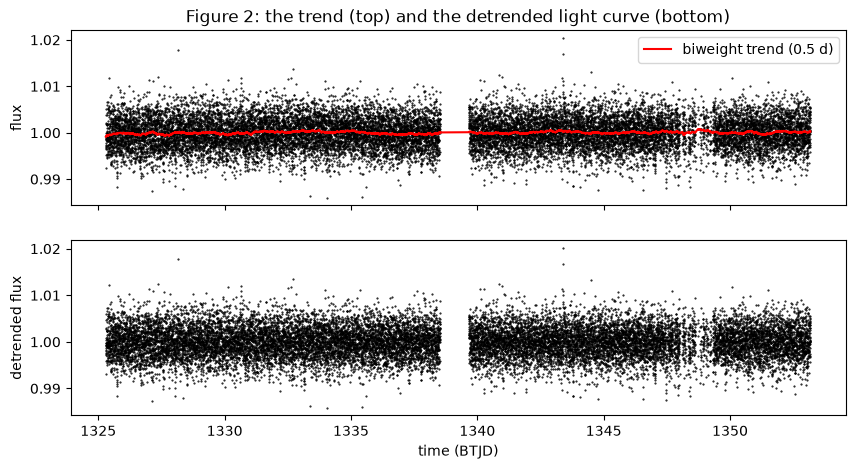

In [3]:
flat_flux, trend = flatten(time, flux, method="biweight", window_length=0.5, return_trend=True)
ok = np.isfinite(flat_flux)
time, flux, flat_flux, trend = time[ok], flux[ok], flat_flux[ok], trend[ok]

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(time, flux, "k.", ms=1)
ax[0].plot(time, trend, "r", lw=1.5, label="biweight trend (0.5 d)")
ax[0].set_ylabel("flux"); ax[0].legend()
ax[0].set_title("Figure 2: the trend (top) and the detrended light curve (bottom)")
ax[1].plot(time, flat_flux, "k.", ms=1)
ax[1].set_xlabel("time (BTJD)"); ax[1].set_ylabel("detrended flux");

## Step 3: search with TLS

Transit Least Squares tries every plausible period, duration and phase with a realistic transit shape and reports
the signal detection efficiency (SDE) per period. It works best when it knows the star: `catalog_info` reads the
limb darkening, mass and radius of the star from the TESS Input Catalog, which sets the range of possible periods
and durations (a small, dense star allows periods of a few hours).

star: R = 0.189 R_sun, M = 0.158 M_sun, limb darkening (a, b) = (np.float64(0.1933), np.float64(0.5347))
Transit Least Squares TLS 2.0.4 (30 Oct 2026)
Creating model cache for 36 durations
Searching 18275 data points, 14655 periods from 0.124 to 9.998 days
Using 1 of 20 CPU threads


period 0.46294 d, SDE 37.1, depth 4509 ppm, duration 0.50 h, 57 transits


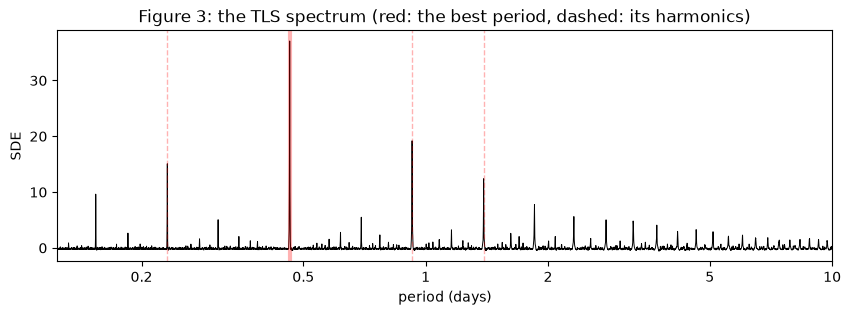

In [4]:
ab, mass, mass_min, mass_max, radius, radius_min, radius_max = catalog_info(TIC_ID=tic)
print(f"star: R = {radius:.3f} R_sun, M = {mass:.3f} M_sun, limb darkening (a, b) = {ab}")

tls = transitleastsquares(time, flat_flux)
found = tls.power(u=ab, R_star=radius, M_star=mass, period_max=10,
                  use_threads=1, show_progress_bar=False)   # one core is enough here (~5 s)
print(f"period {found.period:.5f} d, SDE {found.SDE:.1f}, depth {1e6 * (1 - found.depth):.0f} ppm, "
      f"duration {24 * found.duration:.2f} h, {found.distinct_transit_count} transits")

plt.figure(figsize=(10, 3))
plt.plot(found.periods, found.power, "k", lw=0.7)
plt.axvline(found.period, color="r", alpha=0.3, lw=3)
for n in (2, 3, 0.5):
    plt.axvline(n * found.period, color="r", alpha=0.3, lw=1, ls="--")
plt.xscale("log"); plt.xlim(found.periods.min(), found.periods.max())
plt.xticks([0.2, 0.5, 1, 2, 5, 10], ["0.2", "0.5", "1", "2", "5", "10"]); plt.minorticks_off()
plt.xlabel("period (days)"); plt.ylabel("SDE")
plt.title("Figure 3: the TLS spectrum (red: the best period, dashed: its harmonics)");

An SDE far above 9 (TLS's threshold for a false-alarm probability below 0.01%) is a clear detection. The smaller
peaks at multiples and fractions of the period are its harmonics. Folding at the period shows the transit:

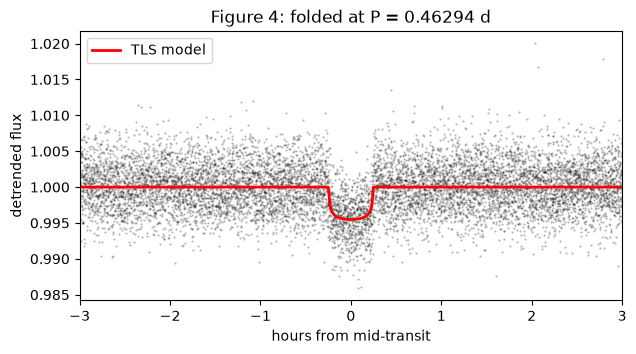

In [5]:
plt.figure(figsize=(7, 3.5))
plt.plot(24 * found.period * (found.folded_phase - 0.5), found.folded_y, "k.", ms=1, alpha=0.3)
plt.plot(24 * found.period * (found.model_folded_phase - 0.5), found.model_folded_model, "r", lw=2, label="TLS model")
plt.xlim(-3, 3); plt.legend()
plt.xlabel("hours from mid-transit"); plt.ylabel("detrended flux")
plt.title(f"Figure 4: folded at P = {found.period:.5f} d");

## Step 4: detrend again, with the transits protected

The first detrending did not know where the transits are, so the trend dipped slightly into each of them and made
them shallower. Now that we know period, phase and duration, we mask the transits (twice their duration) and
detrend again from the original flux.

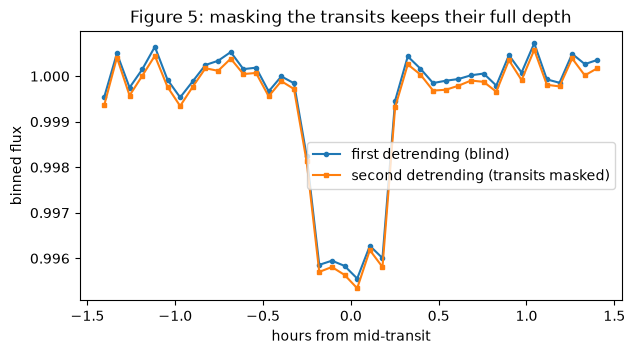

In [6]:
mask = transit_mask(time=time, period=found.period, duration=2 * found.duration, T0=found.T0)
flat2, trend2 = flatten(time, flux, method="biweight", window_length=0.5, return_trend=True, mask=mask)
ok = np.isfinite(flat2)

phase = (time - found.T0 + 0.5 * found.period) % found.period - 0.5 * found.period    # days from mid-transit
bins = np.linspace(-0.06, 0.06, 41)
def binned(y):
    idx = np.digitize(phase, bins)
    return np.array([np.median(y[(idx == i) & ok]) for i in range(1, len(bins))])

centers = 0.5 * (bins[1:] + bins[:-1])
plt.figure(figsize=(7, 3.5))
plt.plot(24 * centers, binned(flat_flux), "o-", ms=3, label="first detrending (blind)")
plt.plot(24 * centers, binned(flat2), "s-", ms=3, label="second detrending (transits masked)")
plt.xlabel("hours from mid-transit"); plt.ylabel("binned flux"); plt.legend()
plt.title("Figure 5: masking the transits keeps their full depth");

## Step 5: fit with importance sampling

pizzetti's `MarginalTransitModel` fits the transit geometry (mid-transit time t0, period, radius ratio Rp/R★,
scaled semi-major axis a/R★, impact parameter b) and integrates the quadratic limb darkening and the flux level out
analytically, over all physically possible limb-darkening profiles. `fit()` samples the posterior by importance
sampling, without MCMC; we ask for 20 000 draws instead of the default 4000 for smooth histograms, which
costs a few seconds. We keep the data within two transit durations of each transit and start from the TLS
values.

In [7]:
near = ok & (np.abs(phase) < 2 * found.duration)
sigma = np.std(flat2[ok & (np.abs(phase) > found.duration)])        # noise per point

params = pizzetti.TransitParams()
params.t0 = found.T0
params.per = found.period
params.rp = found.rp_rs
params.a = found.period / (np.pi * found.duration)                   # a/R* of a central transit of this duration
params.inc = 89.0
params.ecc = 0.0
params.w = 90.0
params.limb_dark = "quadratic"
params.u = list(ab)

model = pizzetti.MarginalTransitModel(params, time[near], flat2[near], sigma, free=["t0", "per", "rp", "a", "b"])
result = model.fit(ld="u", n=20000)          # 20 000 importance draws (default 4000): smoother plots
print(result.summary())
d = result.diagnostics
print(f"\nk-hat {d['khat']:.2f} (below 0.5 is good), effective draws {d['ess']:.0f}, passes its checks: {d['is_ok']}")

              median     -1sigma     +1sigma
t0          1325.726    0.000272    0.000307
per        0.4629262    7.23e-06    6.86e-06
rp        0.06343895     0.00159     0.00159
a           7.043584       0.652       0.307
b           0.282868       0.192       0.224
u1         0.2866152       0.191       0.229
u2        0.08685164       0.233       0.329
f0         0.9999169    6.55e-05     6.6e-05

k-hat 0.23 (below 0.5 is good), effective draws 13157, passes its checks: True


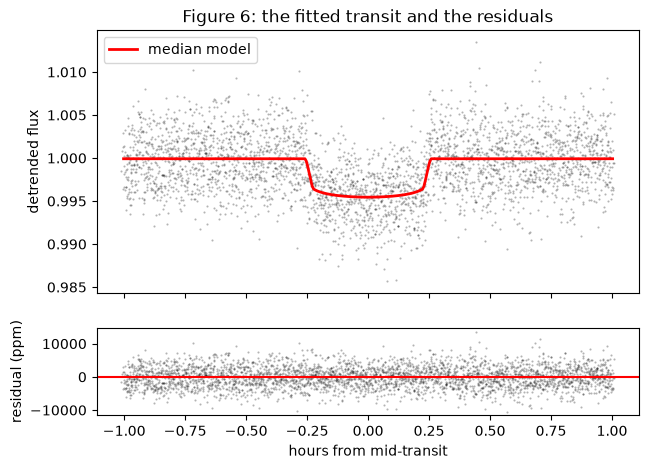

In [8]:
best = dict(zip(result.labels, np.median(result.samples, axis=0)))
fit_params = pizzetti.TransitParams()
fit_params.t0, fit_params.per, fit_params.rp, fit_params.a = best["t0"], best["per"], best["rp"], best["a"]
fit_params.inc = np.degrees(np.arccos(best["b"] / best["a"]))
fit_params.ecc, fit_params.w, fit_params.limb_dark, fit_params.u = 0.0, 90.0, "quadratic", [best["u1"], best["u2"]]

ph = (time[near] - best["t0"] + 0.5 * best["per"]) % best["per"] - 0.5 * best["per"]
model_flux = best["f0"] * pizzetti.TransitModel(fit_params, time[near]).light_curve(fit_params)
t_fine = best["t0"] + np.linspace(-2 * found.duration, 2 * found.duration, 400)
f_fine = best["f0"] * pizzetti.TransitModel(fit_params, t_fine).light_curve(fit_params)

fig, ax = plt.subplots(2, 1, figsize=(7, 5), sharex=True, gridspec_kw=dict(height_ratios=(3, 1)))
ax[0].plot(24 * ph, flat2[near], "k.", ms=1, alpha=0.3)
ax[0].plot(24 * (t_fine - best["t0"]), f_fine, "r", lw=2, label="median model")
ax[0].set_ylabel("detrended flux"); ax[0].legend()
ax[0].set_title("Figure 6: the fitted transit and the residuals")
ax[1].plot(24 * ph, 1e6 * (flat2[near] - model_flux), "k.", ms=1, alpha=0.3)
ax[1].axhline(0, color="r")
ax[1].set_xlabel("hours from mid-transit"); ax[1].set_ylabel("residual (ppm)");

The corner plot shows the posterior of every parameter and every pair. The limb-darkening coefficients u1 and u2
are only weakly constrained by a planet this small, but they are fully accounted for: every point of the
posterior has a physically possible limb-darkening profile.

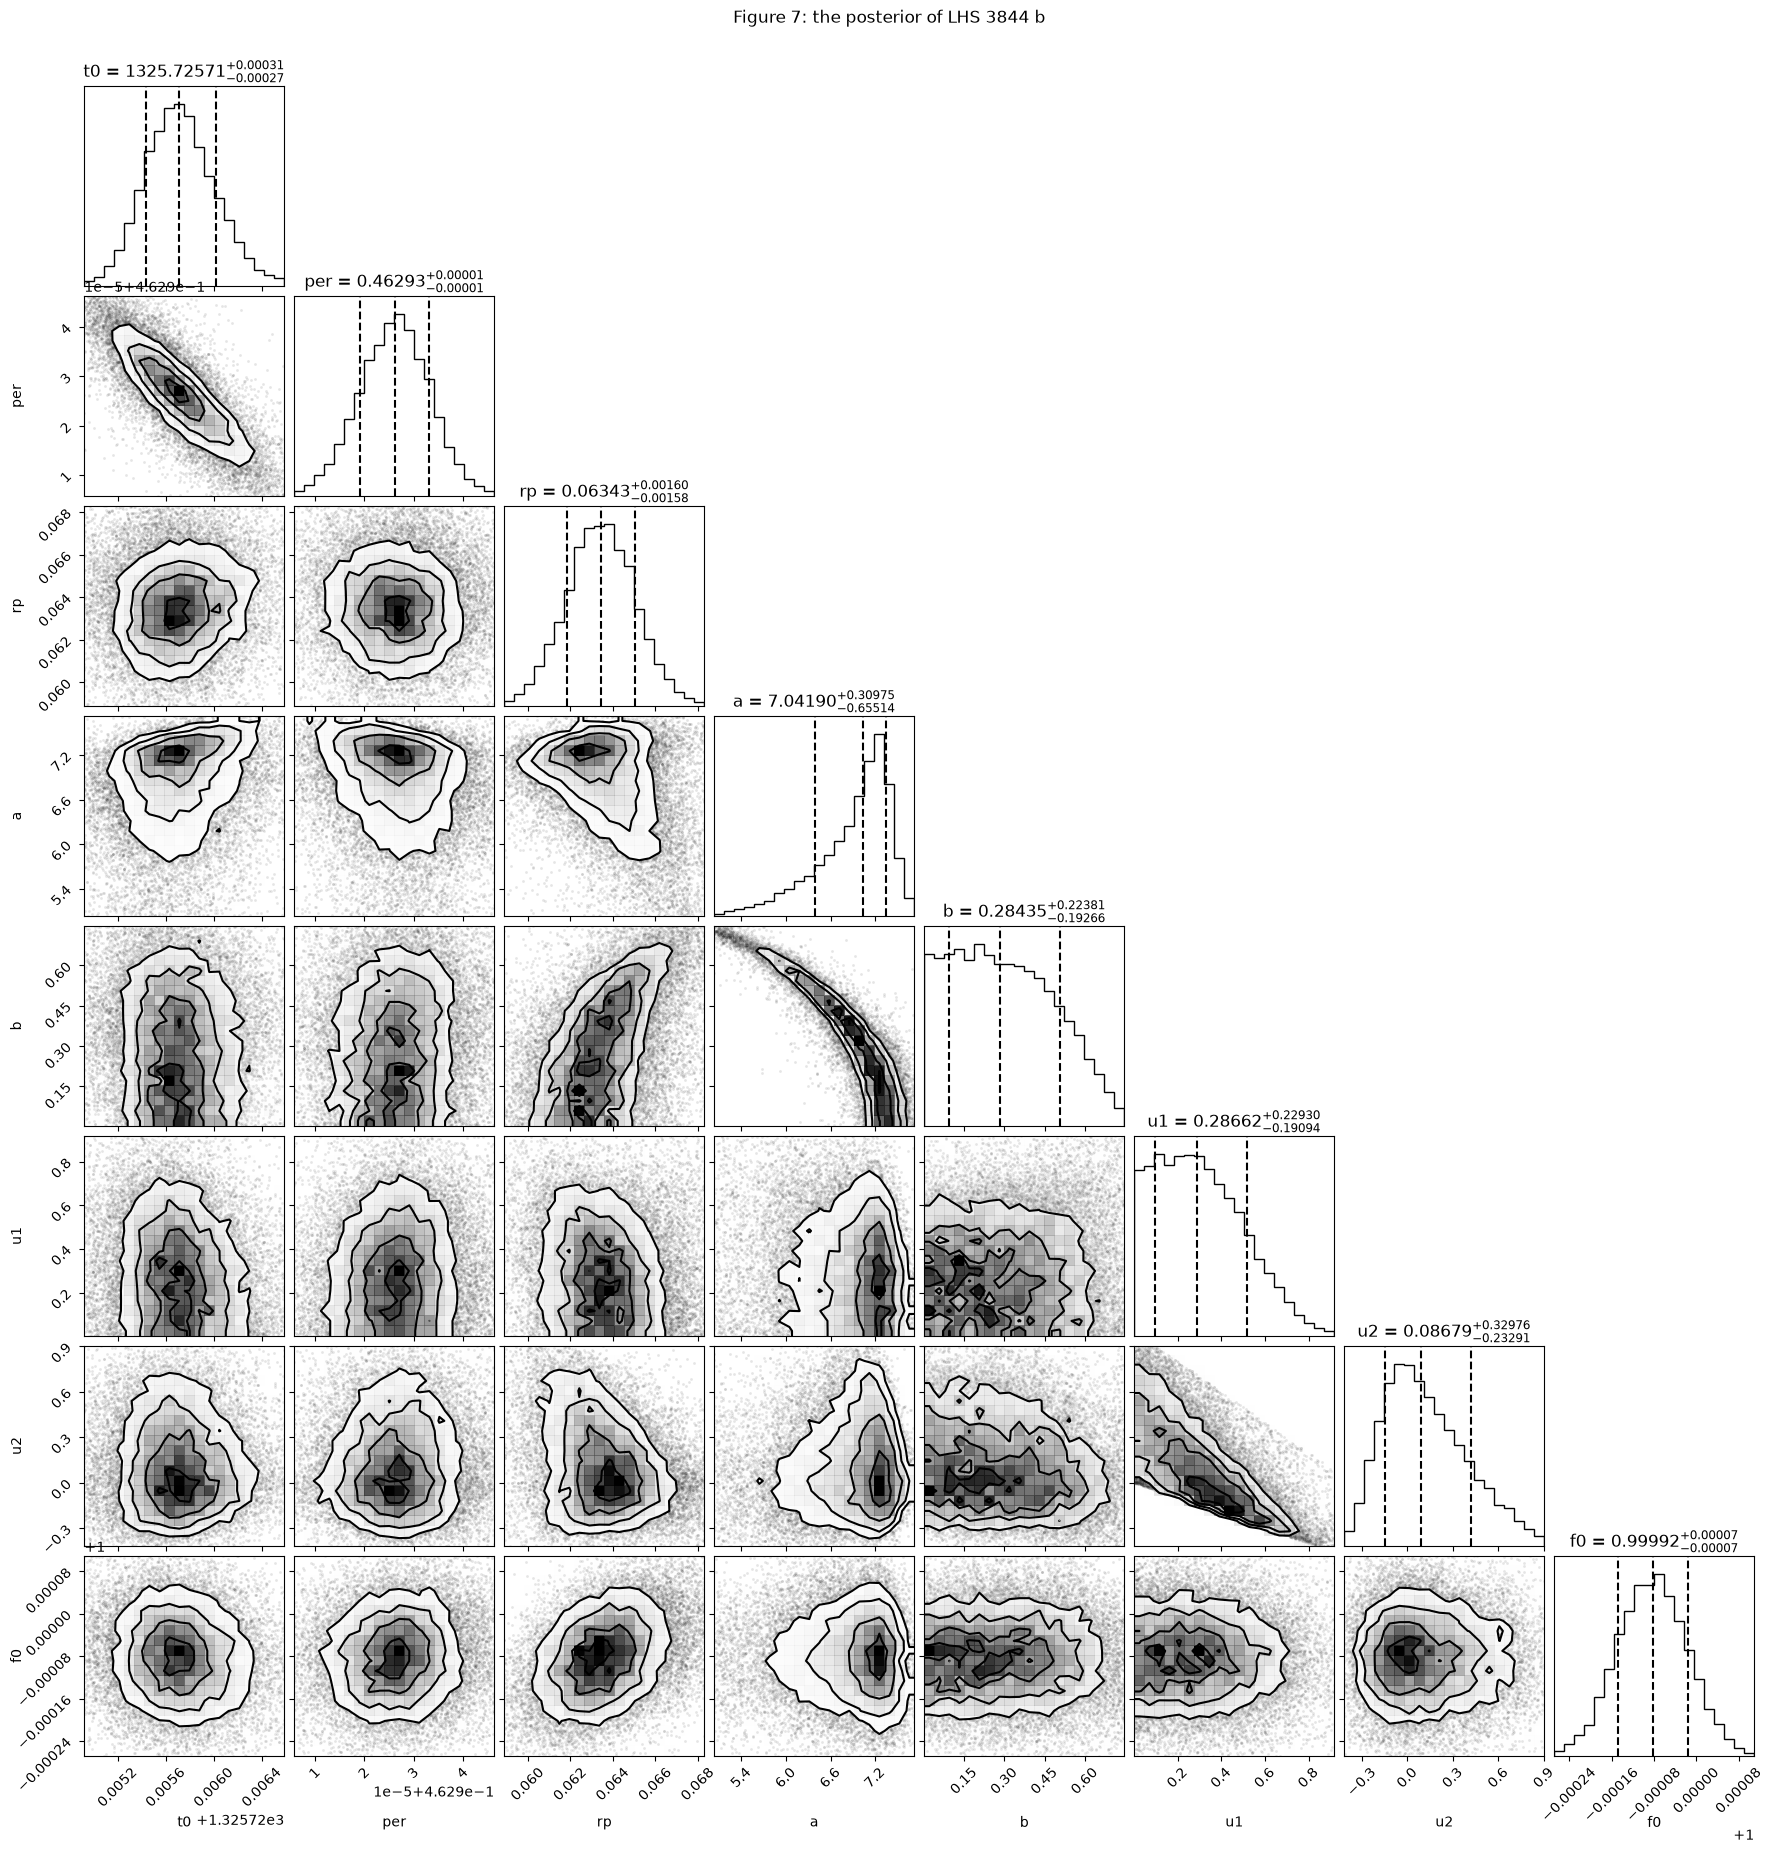

In [9]:
fig = result.corner(range=[0.995] * len(result.labels),   # each axis: the central 99.5% of the posterior
                    show_titles=True, title_fmt=".5f", quantiles=[0.16, 0.5, 0.84])
fig.suptitle("Figure 7: the posterior of LHS 3844 b", y=1.02);

## Step 6: physical quantities

The posterior draws turn directly into physical quantities. With the stellar radius from the catalogue, Rp/R★
gives the planet's radius. And a/R★ with the period gives the density of the star (Kepler's third law),
independent of the catalogue: a check that the fit and the star agree.

planet radius: 1.31 +0.03 -0.03 Earth radii
stellar density: 30.8 +4.2 -7.8 g/cm^3 (catalogue: 33.2)


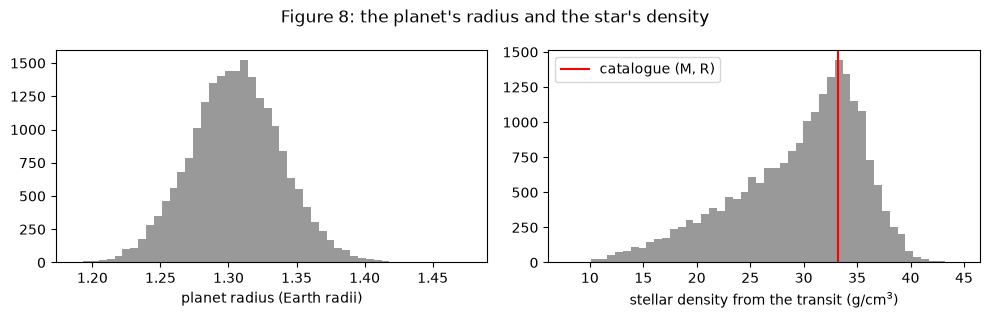

In [10]:
s = dict(zip(result.labels, result.samples.T))
R_sun_in_R_earth = 109.08
G = 6.674e-8                                                         # cgs
radius_planet = s["rp"] * radius * R_sun_in_R_earth                 # Earth radii
rho_star = 3 * np.pi * s["a"]**3 / (G * (s["per"] * 86400)**2)      # g/cm^3
rho_catalog = mass * 1.989e33 / (4 / 3 * np.pi * (radius * 6.957e10)**3)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(radius_planet, bins=50, color="0.6")
ax[0].set_xlabel("planet radius (Earth radii)")
ax[1].hist(rho_star, bins=50, color="0.6")
ax[1].axvline(rho_catalog, color="r", label="catalogue (M, R)")
ax[1].set_xlabel("stellar density from the transit (g/cm$^3$)"); ax[1].legend()
fig.suptitle("Figure 8: the planet's radius and the star's density")
fig.tight_layout()
q = lambda x: np.percentile(x, [16, 50, 84])
r = q(radius_planet); rho = q(rho_star)
print(f"planet radius: {r[1]:.2f} +{r[2] - r[1]:.2f} -{r[1] - r[0]:.2f} Earth radii")
print(f"stellar density: {rho[1]:.1f} +{rho[2] - rho[1]:.1f} -{rho[1] - rho[0]:.1f} g/cm^3 (catalogue: {rho_catalog:.1f})")

LHS 3844 b is a planet of about 1.3 Earth radii on an 11-hour orbit, and the stellar density from the transit
agrees with the catalogue.

## What you learned

- **lightkurve** downloads the light curve; **wotan** removes trends without eating the transits (mask them once
  you know where they are).
- **TLS** finds the planet and gives period, phase, duration and depth; telling it about the star
  (`catalog_info`) sets the right range of periods.
- **pizzetti** fits the transit by importance sampling in seconds, with the limb darkening integrated out over
  all physical profiles; the posterior draws give the planet's radius and the star's density.

**More:** the [wotan tutorials](https://github.com/hippke/wotan/tree/master/tutorials), the
[TLS tutorials](https://github.com/hippke/tls/tree/master/tutorials), and pizzetti's
[first fit with importance sampling](https://github.com/hippke/pizzetti/blob/main/examples/11_your_first_fit_with_is.ipynb) and
[how importance sampling works](https://github.com/hippke/pizzetti/blob/main/examples/12_importance_sampling_from_scratch.ipynb).